In [7]:
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense,Input
from tensorflow.keras.optimizers import Adam

In [8]:
train_data=pd.read_csv('sign_mnist_train.csv')
test_data=pd.read_csv('sign_mnist_test.csv')
y_train=train_data['label'].values
x_train=train_data.drop('label',axis=1).values

y_test=test_data['label'].values
x_test=test_data.drop('label',axis=1).values

In [9]:
x_train=x_train/255.0
x_test=x_test/255.0

In [ ]:
model=Sequential([
    Input(shape=(x_train.shape[1:],)),
    Dense(256,activation='relu'),
    Dense(128,activation='relu'),
    Dense(25,activation='softmax')
])

In [11]:
model.compile(optimizer=Adam(learning_rate=0.001),
             loss='sparse_categorical_crossentropy',
             metrics=['accuracy']
             )

In [12]:
history=model.fit(x_train,y_train,epochs=11,batch_size=64,validation_data=(x_test,y_test))

Epoch 1/11
429/429 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - accuracy: 0.4081 - loss: 1.9758 - val_accuracy: 0.5729 - val_loss: 1.4089
Epoch 2/11
429/429 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.6781 - loss: 1.0317 - val_accuracy: 0.6163 - val_loss: 1.1911
Epoch 3/11
429/429 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.7808 - loss: 0.7044 - val_accuracy: 0.6722 - val_loss: 1.0178
Epoch 4/11
429/429 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.8554 - loss: 0.4695 - val_accuracy: 0.7220 - val_loss: 0.8887
Epoch 5/11
429/429 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9121 - loss: 0.3064 - val_accuracy: 0.7036 - val_loss: 1.0001
Epoch 6/11
429/429 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9392 - loss: 0.2177 - val_accuracy: 0.7480 - val_loss: 0.9175
Epoch 7/11
429/429 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9667 - loss: 0.1367 - val_accuracy: 0.7444 - val_loss: 0.9517
Epoch 8/11
429/429 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.9790 - loss: 0.0951 - val_accuracy: 0.

In [14]:
print("\nEvaluating network on test data...")
test_loss, test_accuracy = model.evaluate(x_test, y_test, verbose=0)
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")


Evaluating network on test data...
Test Loss: 1.0549
Test Accuracy: 75.20%


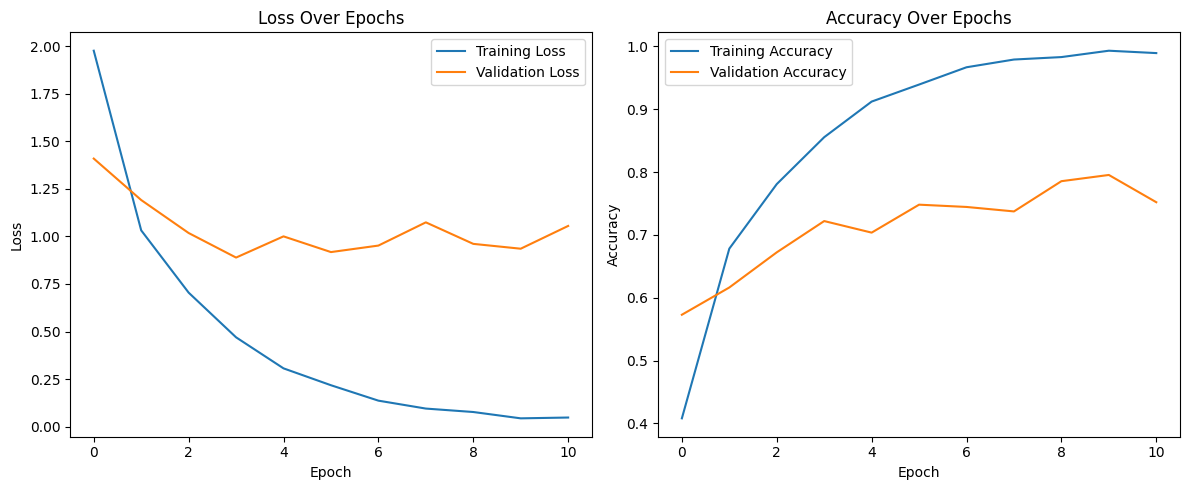

In [15]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Loss Over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()


plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Accuracy Over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.tight_layout()
plt.show()